[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/15_retina_coding_spectrum.ipynb)

# Retina: coding spectrum

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Task 4 of the note *Scale-resolved decomposition of G(x)* for the retina, as notebook 10 for V1 and V4: plot the coding spectrum $\rho(\tau)$ of the W3 and tOFFalpha mosaics against $\tau = \log t$, under the envelope spectrum of notebook 14, from responses to 200 test images, and report $\tfrac12 \int \rho\, d\tau = I(R; X)$ for each cell type.

* **Requirements**: TinyImageNet, the retina checkpoints (downloaded below), a GPU, `multigeom` from the `g-per-scale` branch and `openretina` from the private repository `open-retina-multigeom`.

* **Time**: about 30 min on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3.11 s, sys: 90.1 ms, total: 3.2 s
Wall time: 601 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the models, the test images, the noise scales, the bootstrap, and where the results and the figure go.

<details><summary>Details</summary>

* `load_retina` loads a cell's models with the Poisson noise of its responses (notebook 12), and `load_retina_test_images` the test images in the diffusion model's units (notebook 14). The spectrum is `multigeom.compute_coding_spectrum`, as in notebook 10, given that Poisson noise.

</details>

In [2]:
%%time

import os
from pathlib import Path

import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom import compute_coding_spectrum
from multigeom.analysis import compute_band, compute_bootstrap, compute_information
from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.encoders.retina import load_retina, load_retina_test_images
from multigeom.plotting import plot_coding_spectrum
from multigeom.utils import get_device, load_intermediate, make_generator
from multigeom.utils import save_intermediate

# the parameters of this notebook
PARAMS = {
    # the two cell types and the area of their models (runs/<stage>/lorenzi/<area>/)
    "encoder": "lorenzi",
    "cell_types": {"W3": "retina-W3_176-exp7", "tOFFalpha": "retina-tOFFalpha_17-exp5"},
    # the test images of notebook 14: TinyImageNet training images 50,000 to 50,199
    # in open-retina's shuffled order, standardised together
    "n_test_images": 200,
    "frames": "data/tiny-imagenet-200/train",
    "normalizer": "data/02_intermediate/retina/normalizer.pt",
    # the noisy versions of each image at each noise scale, each with a new response,
    # and how many the network sees at once (100 fit in the GPU's memory at 120 x 120)
    "n_noise": 8,
    "batch_size": 100,
    # the DDPM steps of notebooks 9, 10 and 14
    "timesteps": [1, 2, 5, 10, 20, *range(40, 961, 40), 980, 999],
    # the resamples of the images of the paired bootstrap, and its seed
    "n_bootstrap": 2000,
    "bootstrap_seed": 0,
    # where the computed results are stored, so that a new run reloads them in seconds
    # (True: recompute and overwrite them)
    "intermediate_dir": "data/02_intermediate/15_retina_coding_spectrum",
    "recompute": False,
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/retina/task4",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the estimator and diffusion configs (packaged with multigeom); σ is only the nominal
# value the function asks for: the responses get the Poisson noise of each model
est_cfg = load_config("estimator")
sigma = float(load_config("diffusion").conditioning.observation_noise_sigma)

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 671 ms, sys: 103 ms, total: 773 ms
Wall time: 786 ms


## 2. Download the retina models

The checkpoints of the two cells are on Hugging Face, with those of V1 and V4; only the retina ones are downloaded.

In [3]:
%%time

# download the retina checkpoints into runs/ (files that are already there are kept)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", allow_patterns="*/lorenzi/*"
)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

CPU times: user 15.6 ms, sys: 1.92 ms, total: 17.5 ms
Wall time: 417 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images (240 MB the first time).

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 95 μs, sys: 0 ns, total: 95 μs
Wall time: 78.4 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute the coding spectrum of W3 and tOFFalpha

For each test image, noise scale and noisy version, a response of the mosaic to the image (Poisson spike counts, as the models were trained with), and the error of the denoiser without and with it: $\rho(\tau)$ is what the response takes off the error, per unit of noise variance.

<details><summary>Details</summary>

* **Definition** (the note, eq. 7), as in notebook 10: $\rho(\tau) = \rho^{\rm env}(\tau) - \mathbb{E}\left[\frac1t \lVert \hat x(x_t, r) - x \rVert^2\right]$, with $r \sim p(r \mid x)$. For exact posterior means, $0 \le \rho \le \rho^{\rm env}$ and $\tfrac12 \int \rho\, d\tau = I(R; X)$ in nats.
* **The responses.** $n \sim \mathrm{Poisson}(g \lambda)$ with $\lambda$ the rates of the mosaic's cells and $g$ the exposure of the cell, standardised as in training (`models.noise`).
* **Caveat.** Notebook 14 found that these networks' errors stop falling at $\tau \gtrsim 3.6$; the coarse end of $\rho$ inherits that.
* **Stored results.** In `data/02_intermediate/15_retina_coding_spectrum/`.

</details>

In [5]:
%%time

# the spectra, reloaded if stored, else computed and stored; spectra[cell_type] holds,
# per image and noise scale, the errors without and with the responses
results_file = Path(PARAMS["intermediate_dir"]) / "results.pt"
if results_file.exists() and not PARAMS["recompute"]:
    spectra = load_intermediate(results_file)
else:
    spectra, frames = {}, Path(PARAMS["frames"])
    for cell_type, area in PARAMS["cell_types"].items():
        # the cell's models, and the test images in the diffusion model's units
        models = load_retina(
            area, Path("runs"), frames, device, normalizer_cache=PARAMS["normalizer"]
        )
        images = load_retina_test_images(models, frames, n=PARAMS["n_test_images"])

        # the coding spectrum of every image, with the Poisson noise of the model
        spectra[cell_type] = compute_coding_spectrum(
            images,
            models.encoder,
            models.unet,
            models.alphas_cumprod,
            PARAMS["timesteps"],
            device,
            sigma=sigma,
            n_noise=PARAMS["n_noise"],
            batch_size=PARAMS["batch_size"],
            generator=make_generator(int(est_cfg.seed), device),
            noise=models.noise,
        )
        print(cell_type, "done:", tuple(spectra[cell_type].env.shape))
    save_intermediate(spectra, results_file)

/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/steeve/miniconda3/envs/tutorials-env/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.


W3 done: (200, 31)


tOFFalpha done: (200, 31)
CPU times: user 26min 45s, sys: 5min 47s, total: 32min 33s
Wall time: 32min 28s


## 5. Plot the coding spectrum

A: $\rho(\tau)$ of W3 and tOFFalpha on the same axes as the envelope spectrum $\rho^{\rm env}(\tau)$ (the W3 model's), on a linear axis; the legend gives $\tfrac12 \int \rho\, d\tau$ of each cell type. B: each $\rho(\tau)$ over its own maximum. The bands are 95% intervals from a paired bootstrap over the test images, as in notebook 10. The figure is also saved to `assets/figures/retina/task4/coding_spectrum.png`; the cell prints the values the conclusion uses.

W3: ½∫ρ dτ = 1.79 ± 0.36 nats (2.6 bits)
tOFFalpha: ½∫ρ dτ = -0.10 ± 0.18 nats (-0.1 bits)
  tau |   rho W3 | rho tOFFalpha |  rho^env
 -8.4 |   -0.358 |        -0.012 | 4.07e+03
 -7.9 |   -0.161 |        -0.208 | 3.71e+03
 -7.0 |    0.102 |        -0.101 | 3.15e+03
 -6.1 |    0.147 |        -0.206 | 2.65e+03
 -5.1 |    0.259 |        -0.100 | 2.06e+03
 -3.9 |    0.335 |        -0.078 | 1.43e+03
 -2.6 |    0.317 |        -0.110 |      846
 -1.8 |    0.274 |        -0.089 |      572
 -1.2 |    0.348 |         0.022 |      413
 -0.6 |    0.480 |         0.044 |      311
 -0.2 |    0.619 |         0.054 |      239
  0.2 |    0.562 |         0.069 |      185
  0.6 |    0.593 |         0.074 |      145
  1.0 |    0.530 |         0.107 |      113
  1.4 |    0.492 |         0.093 |     87.9
  1.8 |    0.393 |         0.112 |     68.1
  2.3 |    0.274 |         0.052 |     51.6
  2.7 |    0.245 |         0.082 |     38.8
  3.2 |    0.232 |         0.119 |     28.7
  3.6 |    0.170 |         0.

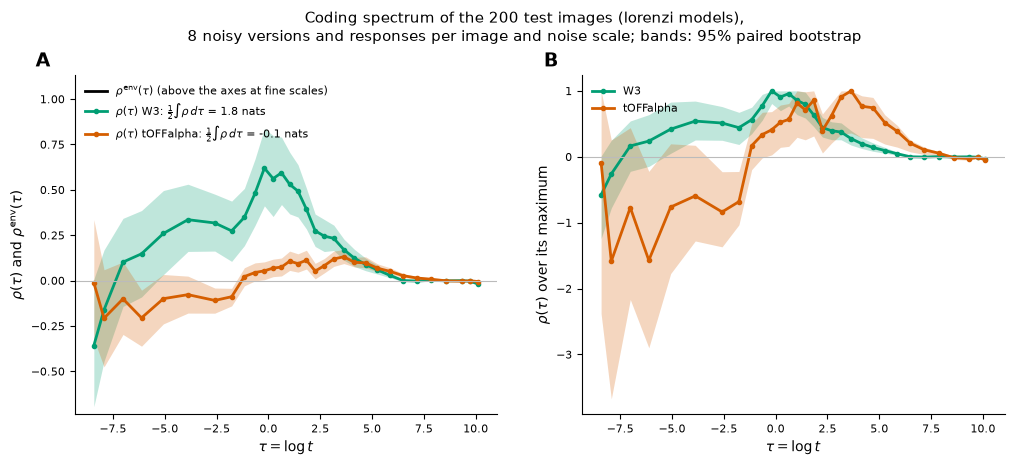

In [6]:
%%time

# 1. the paired bootstrap: the same resamples of the images for both cell types
curves = {name: (s.env - s.coded).double().numpy() for name, s in spectra.items()}
bootstrap = compute_bootstrap(curves, PARAMS["n_bootstrap"], PARAMS["bootstrap_seed"])

# 2. the figure, with the 95% band of each curve, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, plotted = plot_coding_spectrum(spectra, bootstrap, PARAMS)
fig.savefig(
    figure_dir / "coding_spectrum.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

# 3. for each cell type: ½ ∫ ρ dτ in nats (and bits), with its standard error
for name, spectrum in spectra.items():
    mean, sem = compute_information(spectrum.env - spectrum.coded, spectrum.log_tau)
    bits = mean / torch.log(torch.tensor(2.0))
    print(f"{name}: ½∫ρ dτ = {mean:.2f} ± {sem:.2f} nats ({bits:.1f} bits)")

# 4. ρ of each cell type at each noise scale, against ρ^env
log_t = plotted["log_t"]
env = spectra["W3"].env.double().mean(dim=0).numpy()
rho = {name: s.rho.double().numpy() for name, s in spectra.items()}
print("  tau |   rho W3 | rho tOFFalpha |  rho^env")
for level in range(len(log_t)):
    print(
        f"{log_t[level]:5.1f} | {rho['W3'][level]:8.3f} |"
        f" {rho['tOFFalpha'][level]:13.3f} | {env[level]:8.3g}"
    )

# 5. the paired comparison of the curves over their maxima: the noise scales where
# tOFFalpha - W3 is above or below 0 in 95% of the resamples
difference = bootstrap["tOFFalpha"]["normalized"] - bootstrap["W3"]["normalized"]
low, high = compute_band(difference)
print("tOFFalpha above W3 (over their maxima) at tau =", log_t[low > 0].round(1))
print("tOFFalpha below W3 (over their maxima) at tau =", log_t[high < 0].round(1))

## 6. Conclusion

* **What we computed.** The coding spectrum $\rho(\tau)$ of the W3 (cell 176-exp7) and tOFFalpha (cell 17-exp5) mosaics on 200 test images at 31 noise scales, with Poisson responses (about 32 min on one GPU). The figure is in `assets/figures/retina/task4/`.
* **The coarse end is clean.** Unlike $\rho^{\rm env}$ (notebook 14), $\rho$ falls to zero at $\tau \gtrsim 6.5$ for both cell types: the error floor of the networks is the same with and without the responses, so it cancels in the difference.
* **W3 carries information at fine and middle scales, tOFFalpha at coarser ones.** W3 peaks at $\tau \approx -0.2$ to 0.6 (about 0.6). tOFFalpha's curve is small and peaks at $\tau \approx 3.6$ (about 0.13); over their maxima, tOFFalpha lies above W3 from $\tau = 3.6$ to 7.9 and below it from $-6.1$ to 0.6 in 95% of the bootstrap resamples.
* **But tOFFalpha's $\rho$ is negative at fine scales** ($-0.1$ to $-0.2$ from $\tau = -7.9$ to $-1.8$, significantly below 0): there, its denoiser does worse with the responses than without, which no exact posterior mean does. Its $\tfrac12 \int \rho\, d\tau$, $-0.10 \pm 0.18$ nats, is therefore not an estimate of $I(R; X)$; W3's, $1.79 \pm 0.36$ nats, is a lower bound at best, as W3 too is negative at the two finest scales. Both are far below V1 and V4 (6.2 and 9.3 nats, notebook 10).
* **Next steps.** Check the conditional branch of the tOFFalpha model at fine scales (the training of these models, notebook 14), before reading the information values.